# 02 - Critical positions (Stockfish)

**Question:** in how many positions is there only one good move (all others clearly worse), and how often do players of different Elo find that move - broken down by the piece that had to be moved.

**Definition of a critical position:** Stockfish computes the two best moves (MultiPV=2). We compare their *winning chances* (not raw centipawns). If `win_prob(best) - win_prob(second) >= 0.20`, the position is critical. Then every move other than the best one is at least that much worse, so `found_best == False` means a real mistake.

**Requires:** a Stockfish executable (.exe) - download it from https://stockfishchess.org/download/ (Windows), unzip it and copy the .exe file to the `engine/` folder in the project as `stockfish.exe`.

In [1]:
# Windows + Jupyter: without this python-chess cannot start the engine (NotImplementedError)
import asyncio, sys
if sys.platform == 'win32':
    asyncio.set_event_loop_policy(asyncio.WindowsProactorEventLoopPolicy())

sys.path.append('../src')

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from critical import find_critical_positions

# >>> put the Stockfish (.exe) file in the engine/ folder of the project <<<
ENGINE_PATH =r"C:\Users\him3c\Documents\Praca magisterska\chess-features-thesis\stockfish\stockfish-windows-x86-64-universal.exe"   # put the Stockfish file here and name it stockfish.exe
PGN_PATH = '../data/lichess_db_standard_rated_2026-08.pgn.zst' # or ../data/sample.pgn

## 1. Check that the engine works
It should print the two best moves from the starting position. If there is a path error, fix `ENGINE_PATH`.

In [2]:
import chess, chess.engine

with chess.engine.SimpleEngine.popen_uci(ENGINE_PATH) as eng:
    infos = eng.analyse(chess.Board(), chess.engine.Limit(depth=10), multipv=2)
    for i in infos:
        print(i['pv'][0], i['score'])

e2e4 PovScore(Cp(+24), WHITE)
d2d4 PovScore(Cp(+13), WHITE)


## 1b. Registry of analysed games
To avoid analysing the same games twice, every analysis saves the game to the registry `../data/analysed_games.csv` (key = the game's Lichess URL) together with the number of critical positions found:

- `complete = True` - **all** positions of the game were analysed, so `n_critical` is exact (0, 1, 2, ...),
- `complete = False` - partial analysis (e.g. stopped after finding 2 critical positions), so `n_critical` is only "at least this many"; the true number is **unknown**.

Later analyses (sections 2, 2b, 2c) received the `registry_path` parameter and skip games that are in the registry.

In [3]:
from registry import backfill_registry, load_registry, critical_distribution, export_registry_xlsx

REGISTRY_CSV  = '../data/analysed_games.csv'
REGISTRY_XLSX = '../data/analysed_games.xlsx'


In [4]:
# Registry preview + export to Excel (sheets: partie = games / rozklad_krytycznych = distribution / opis = legend)
reg = load_registry(REGISTRY_CSV)
print(f"{len(reg)} games in the registry, of which fully analysed: {int(reg['complete'].sum())}")
display(critical_distribution(reg))

# close the file in Excel before saving, otherwise Windows will lock it
export_registry_xlsx(REGISTRY_CSV, REGISTRY_XLSX)

11641 games in the registry, of which fully analysed: 3514


,critical_positions_per_game,games,share
0,0 (certain),541,0.0465
1,1 (certain),530,0.0455
2,2 (certain),493,0.0424
3,3 (certain),447,0.0384
4,4 (certain),363,0.0312
5,5+ (certain),1140,0.0979
6,"unknown - partial analysis, 0 found",6397,0.5495
7,"unknown - partial analysis, 1 or more found",1730,0.1486


saved: ../data/analysed_games.xlsx


## 2. Game analysis (SLOW, resumable)
Results are appended to `../data/critical_positions.csv` every few games. **You can interrupt the cell at any time (Stop) and run it again - the program skips games that are already done and continues.**

- `max_games=None` = the whole file. Note: a monthly Lichess dump has tens of millions of games - it cannot be analysed in full (one game ≈ a few seconds). Realistically: a few thousand games.
- `quota_edges` + `games_per_bin` = collect the same number of games in each Elo bin (mean Elo of both players), so that the sample is meaningful for very weak and very strong players too. It stops when all bins are full.
- The Elo bins used for ANALYSIS (section 3) are independent - you can change them without recomputing.

In [5]:
CSV_PATH = '../data/critical_positionsv2.csv'

df = find_critical_positions(
    PGN_PATH,
    ENGINE_PATH,
    output_csv=CSV_PATH,
    max_games=None,                        # None = until the end of the file / until the quotas are full
    quota_edges=[0, 1200, 1600,2400 ,4000],  # bins used for sampling
    games_per_bin=500,                     # number of games per bin
    sample_prob=0.01,
    depth=12,
    gap_threshold=0.20,
    min_ply=8,
    threads=4,                             # set to ~ the number of CPU cores
    save_every=10,
    registry_path=REGISTRY_CSV,   # skips games in the registry and adds the new ones
)
print(df.shape)

games analysed: 2135it [00:00, ?it/s]


(132460, 18)


## 2b. Search for critical positions until there are as many as needed
Positions within a game are checked in random order; a game with no critical positions is simply skipped and the program moves on to the next one - it keeps searching **until every Elo bin has `target_per_bin` critical positions**. The bins refer to the Elo of the player who was to move. Only critical positions are saved, to `critical_random.csv` (resumable: you can interrupt and run again).

From this set you can compute: *among critical positions, how often the best move was found - by Elo and piece*. You cannot compute from it the share of critical positions among all positions (section 2 is for that).

In [7]:
from critical import collect_critical_positions

CSV_RANDOM = '../data/critical_randomv2.csv'

dfc = collect_critical_positions(
    PGN_PATH,
    ENGINE_PATH,
    output_csv=CSV_RANDOM,
    target_per_bin=100,                        # number of critical positions in EACH Elo bin
    elo_edges=[0, 1200, 1600,2400 ,4000],     # None = one common target
    depth=12,
    gap_threshold=0.20,
    max_critical_per_game=2,                   # max positions from one game
    max_positions_per_game=40,                 # how many random positions to check in a game
    sample_prob=1.0,                           # <1.0 = a random fraction of games from the whole file
    threads=4,
    registry_path=REGISTRY_CSV,   # skips games in the registry and adds the new ones
)
dfc.shape

critical positions found: 100%|██████████| 400/400 [00:00<?, ?it/s]

found per bin: {0: 100, 1: 100, 2: 100, 3: 100} | games scanned this run: 0


(400, 18)

In [8]:
bins = [0, 1200, 1600,2400 ,4000]   # you can change the bins for the analysis here
labels = ['<1200', '1200-1600', '1600-2400', '2400+']
dfc = pd.read_csv(CSV_RANDOM)
dfc['elo_bin'] = pd.cut(dfc['player_elo'], bins=bins, labels=labels)

pd.DataFrame({
    'critical_positions': dfc.groupby('elo_bin', observed=True).size(),
    'found_best_rate': dfc.groupby('elo_bin', observed=True)['found_best'].mean(),
})

,critical_positions,found_best_rate
elo_bin,,
<1200,100,0.66
1200-1600,100,0.84
1600-2400,100,0.83
2400+,100,0.85


## 2c. The same number of critical positions for every piece
Collects critical positions so that **the best move of each piece** (pawn, knight, bishop, rook, queen, king) has the same number of cases (`target_per_piece`). Results go to `critical_by_piece.csv` (resumable).

- `elo_edges=None` - `target_per_piece` per piece, with no Elo split.
- `elo_edges=[...]` - `target_per_piece` positions in **each piece × Elo bin pair** (6 × 4 × target). This way both pieces and Elo are equal at the same time - but it is a lot of positions, so start with a small target (e.g. 10-30).
- Queen, bishop and king are rarely the only good move, so filling them may take long - you can interrupt the cell at any time.
- Compare the share of moves found **piece by piece**; the overall average from such a sample is not representative.

In [9]:
from critical import collect_critical_by_piece

CSV_PIECE = '../data/critical_by_piecev2.csv'

dfp = collect_critical_by_piece(
    PGN_PATH,
    ENGINE_PATH,
    output_csv=CSV_PIECE,
    target_per_piece=30,        # number of positions in EACH pair (piece x Elo bin); 6 pieces x 4 bins x 30 = 720
    elo_edges=[0, 1200, 1600, 2400, 4000],   # equal across pieces AND Elo; None = pieces only
    depth=12,
    gap_threshold=0.20,
    max_critical_per_game=2,
    max_positions_per_game=40,
    sample_prob=1.0,
    threads=4,
    registry_path=REGISTRY_CSV,   # skips games in the registry and adds the new ones
)
dfp.shape

critical positions found: 100%|██████████| 720/720 [00:00<?, ?it/s]

found per piece (rows) / Elo bin (columns):
         0   1   2   3
bishop  30  30  30  30
king    30  30  30  30
knight  30  30  30  30
pawn    30  30  30  30
queen   30  30  30  30
rook    30  30  30  30
games scanned this run: 0


(720, 18)

In [10]:
dfp = pd.read_csv(CSV_PIECE)
dfp['elo_bin'] = pd.cut(dfp['player_elo'], bins=[0, 1200, 1600, 2400, 4000],
                        labels=['<1200', '1200-1600', '1600-2000', '2000+'])

# check: number of positions in each piece x Elo pair (should be equal)
display(pd.crosstab(dfp['best_piece'], dfp['elo_bin']))

# share of best moves found - by piece
by_piece = dfp.groupby('best_piece').agg(n=('found_best', 'size'), found_best_rate=('found_best', 'mean'))
display(by_piece)

# ... and by piece x Elo (watch out for small n in the cells)
pd.crosstab(dfp['best_piece'], dfp['elo_bin'], values=dfp['found_best'], aggfunc='mean').round(2)

elo_bin,<1200,1200-1600,1600-2000,2000+
best_piece,,,,
bishop,30,30,30,30
king,30,30,30,30
knight,30,30,30,30
pawn,30,30,30,30
queen,30,30,30,30
rook,30,30,30,30


,n,found_best_rate
best_piece,,
bishop,120,0.791667
king,120,0.800000
knight,120,0.725000
pawn,120,0.833333
queen,120,0.733333
rook,120,0.775000


elo_bin,<1200,1200-1600,1600-2000,2000+
best_piece,,,,
bishop,0.83,0.70,0.77,0.87
king,0.70,0.77,0.90,0.83
knight,0.67,0.70,0.83,0.70
pawn,0.77,0.80,0.97,0.80
queen,0.47,0.77,0.90,0.80
rook,0.77,0.73,0.83,0.77


## 3. Basic statistics

In [11]:
# Load the saved results - there is NO need to run Stockfish again
df = pd.read_csv('../data/critical_positionsv2.csv')

# >>> you can freely change the Elo bins here <<<
bins = [0, 1200, 1600,2400, 4000]
labels = ['<1200' ,'1200-1600', '1600-2400', '2400-4000']
df['elo_bin'] = pd.cut(df['player_elo'], bins=bins, labels=labels)

crit = df[df['is_critical']].copy()
print(f"Analysed {len(df)} positions from {df['game_id'].nunique()} games, critical: {len(crit)} ({len(crit)/len(df):.1%})")

summary = pd.DataFrame({
    'positions': df.groupby('elo_bin', observed=True).size(),
    'critical': crit.groupby('elo_bin', observed=True).size(),
    'found_best_rate': crit.groupby('elo_bin', observed=True)['found_best'].mean(),
})
summary['critical_share'] = summary['critical'] / summary['positions']
summary

Analysed 132460 positions from 2135 games, critical: 8697 (6.6%)


,positions,critical,found_best_rate,critical_share
elo_bin,,,,
<1200,28226,1858,0.668999,0.065826
1200-1600,27574,1838,0.733950,0.066657
1600-2400,38277,2429,0.781803,0.063458
2400-4000,38383,2572,0.830093,0.067009


## 4. The piece that had to be moved × player Elo
`best_piece` = the piece that makes the best move. Cells with few cases (< `MIN_N`) are greyed out - the result there is random.

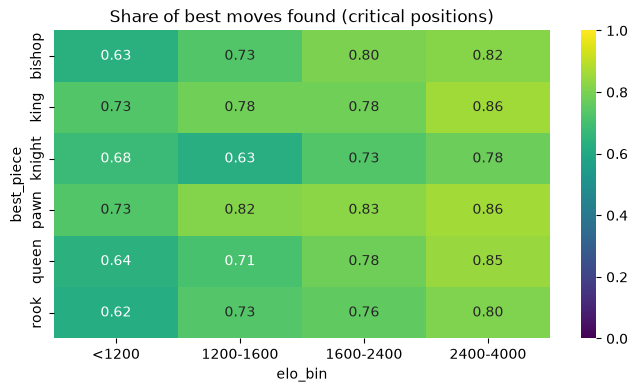

elo_bin,<1200,1200-1600,1600-2400,2400-4000
best_piece,,,,
bishop,304,276,380,339
king,176,197,279,396
knight,279,281,354,325
pawn,415,396,504,582
queen,411,414,487,402
rook,273,274,425,528


In [12]:
MIN_N = 20

g = crit.groupby(['best_piece', 'elo_bin'], observed=True)['found_best'].agg(n='count', rate='mean').reset_index()
rate = g.pivot(index='best_piece', columns='elo_bin', values='rate')
n = g.pivot(index='best_piece', columns='elo_bin', values='n')
rate_masked = rate.where(n >= MIN_N)

plt.figure(figsize=(8, 4))
sns.heatmap(rate_masked, annot=True, fmt='.2f', cmap='viridis', vmin=0, vmax=1)
plt.title('Share of best moves found (critical positions)')
plt.show()
n

## 5. Which pieces players move when they make a mistake
Rows = piece of the best move, columns = piece actually moved (only critical positions in which the player made a mistake).

In [22]:
errors = crit[~crit['found_best']]
pd.crosstab(errors['best_piece'], errors['played_piece'], normalize='index').round(2)

played_piece,bishop,king,knight,pawn,queen,rook
best_piece,,,,,,
bishop,0.25,0.11,0.18,0.20,0.14,0.11
king,0.07,0.53,0.09,0.09,0.06,0.15
knight,0.14,0.10,0.29,0.20,0.14,0.13
pawn,0.16,0.15,0.16,0.25,0.12,0.16
queen,0.14,0.07,0.13,0.19,0.36,0.11
rook,0.11,0.14,0.12,0.17,0.14,0.32


## 6. Buckets: piece × file × half of the board (real distribution)
Data from `critical_positions.csv` - **all** analysed positions, without equalising pieces, so the numbers in the buckets are what came out of the games. (The Elo distribution depends only on the quotas set in section 2.)

A bucket depends on the square the piece making the **best** move starts from:
- **piece**: pawn / knight / bishop / rook / queen / king,
- **file** a-h (left to right from White's perspective),
- **half**: "our" (ranks 1-4 for White, 5-8 for Black) or "the opponent's".

For each bucket: how many positions there were (`n_positions`), how many critical (`n_critical`, `critical_share`) and how often the player found the best move (`found_rate` with a 95% Wilson interval). Grey cells have fewer than `MIN_N` critical positions - the result there is random.

In [14]:
import importlib, buckets as bk
importlib.reload(bk)          # after changing buckets.py there is no need to restart the kernel

MIN_N = 10                    # minimum number of critical positions needed to show the rate

dfn = pd.read_csv('../data/critical_positionsv2.csv')
dfn = bk.add_bucket_columns(dfn)
print(f"{len(dfn)} positions from {dfn['game_id'].nunique()} games, of which critical: {int(dfn['is_critical'].sum())}")
bk.summarize(dfn, ['best_piece'])

132460 positions from 2135 games, of which critical: 8697


,best_piece,n_positions,n_critical,n_found,critical_share,found_rate,ci_low,ci_high
0,pawn,33197,1897,1542,0.057144,0.812862,0.794685,0.829775
1,knight,21811,1239,875,0.056806,0.706215,0.680245,0.730909
2,bishop,19737,1299,977,0.065815,0.752117,0.727915,0.774832
3,rook,20764,1500,1117,0.072240,0.744667,0.721994,0.766089
4,queen,18576,1714,1275,0.092270,0.743874,0.722680,0.763977
5,king,18375,1048,840,0.057034,0.801527,0.776296,0.824555


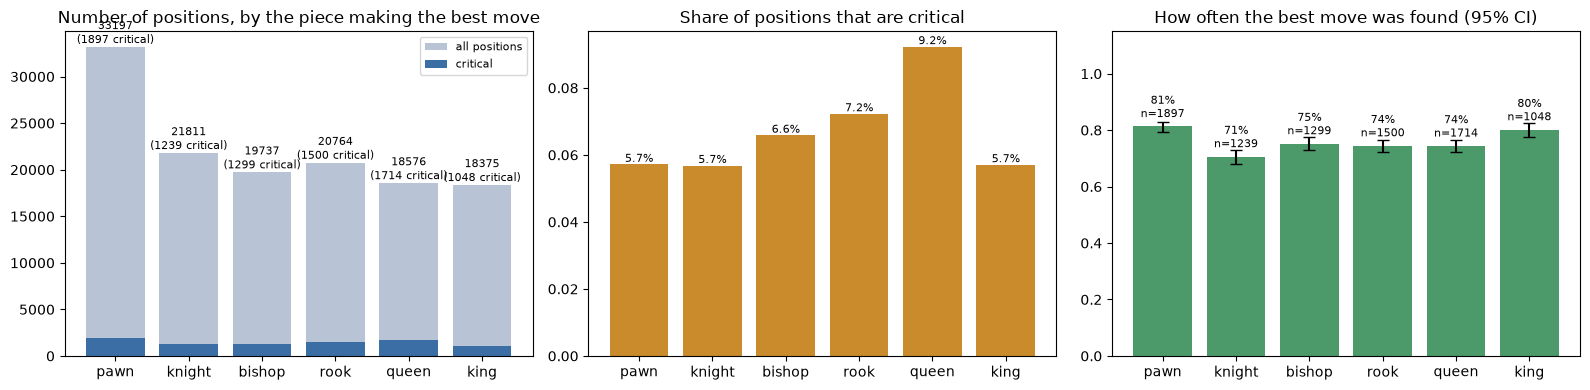

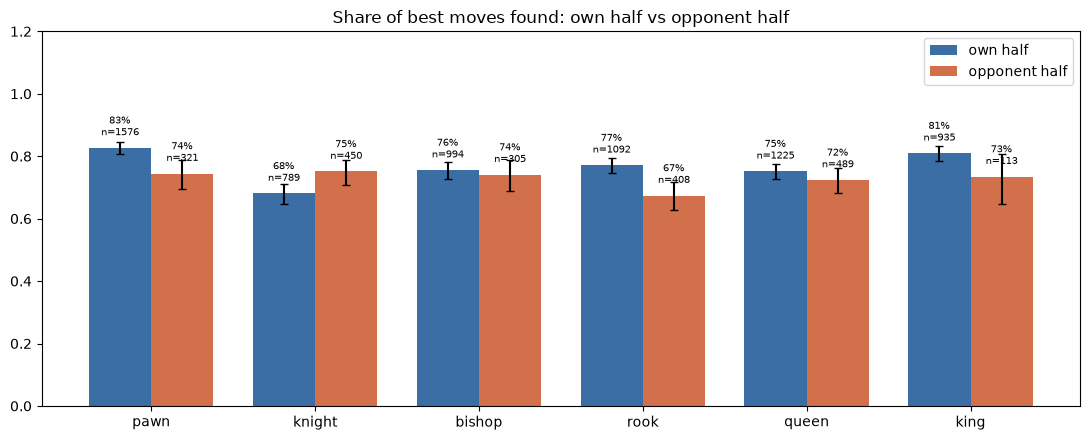

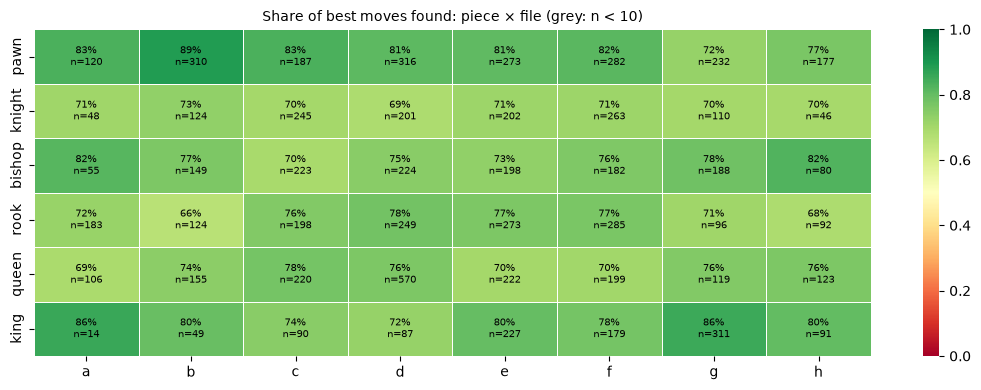

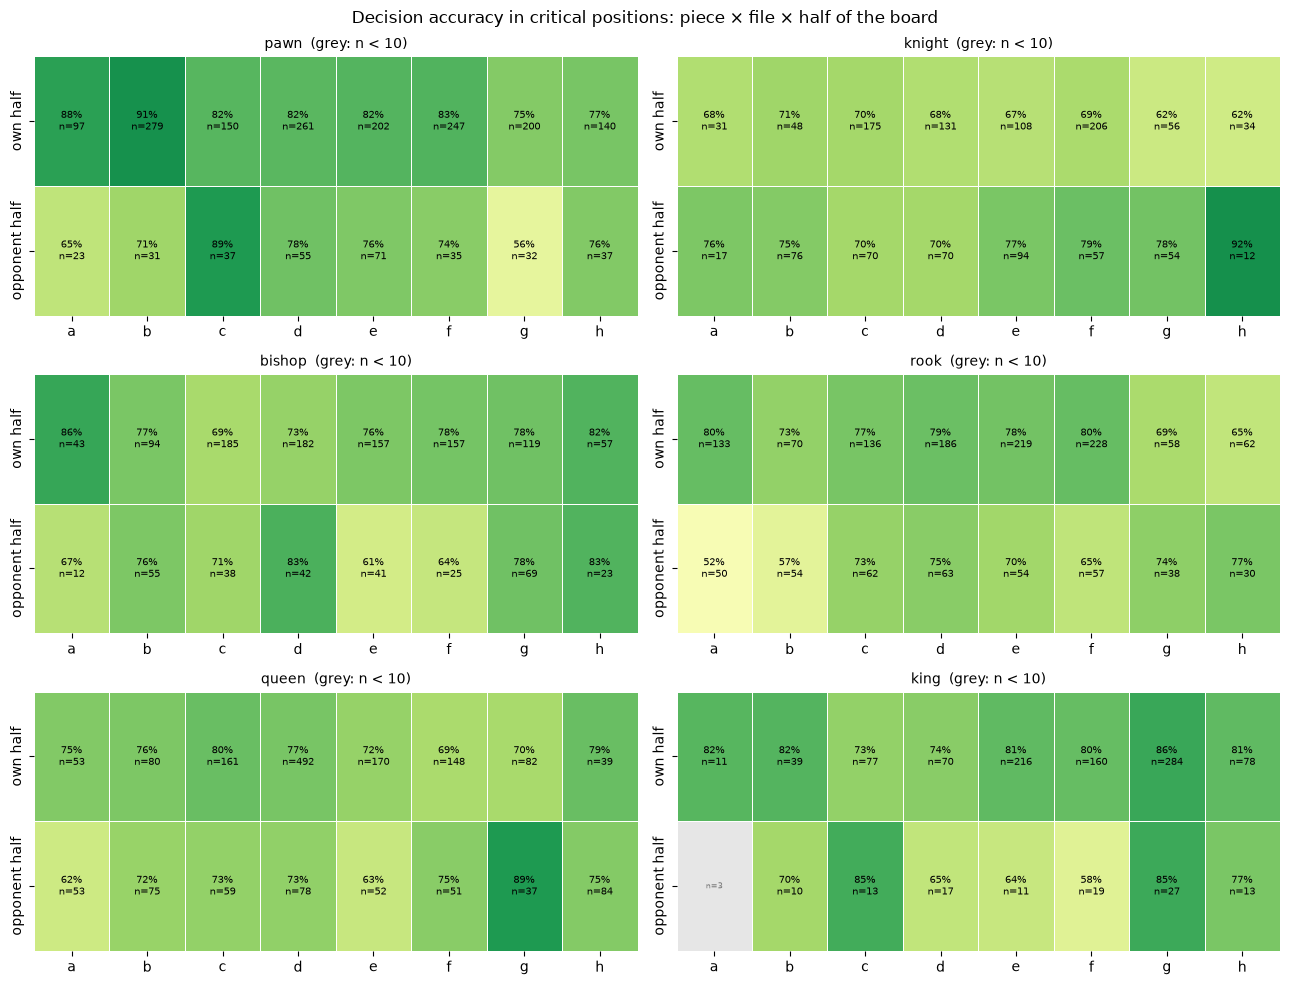

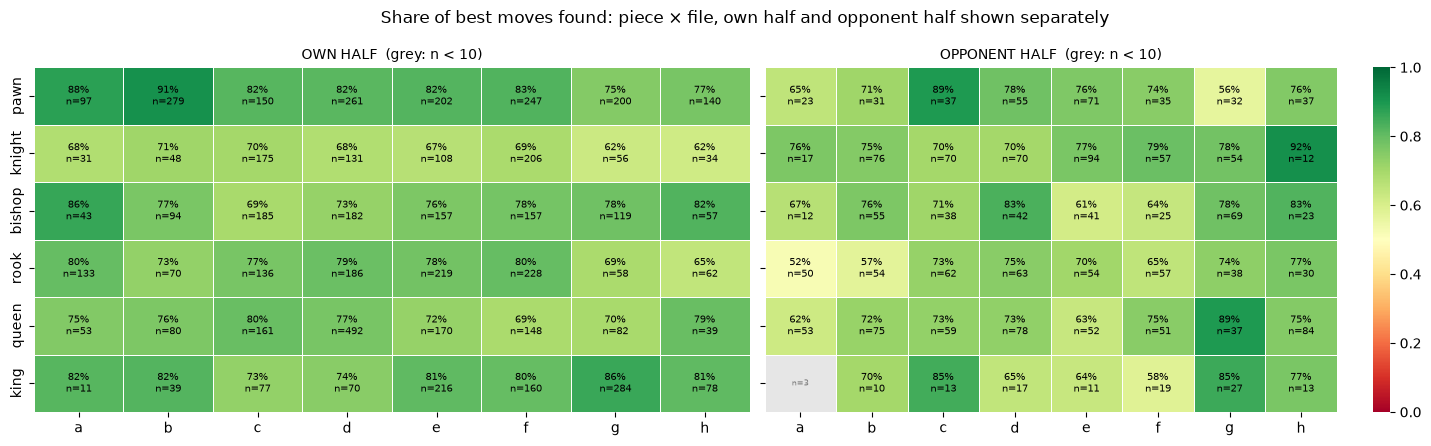

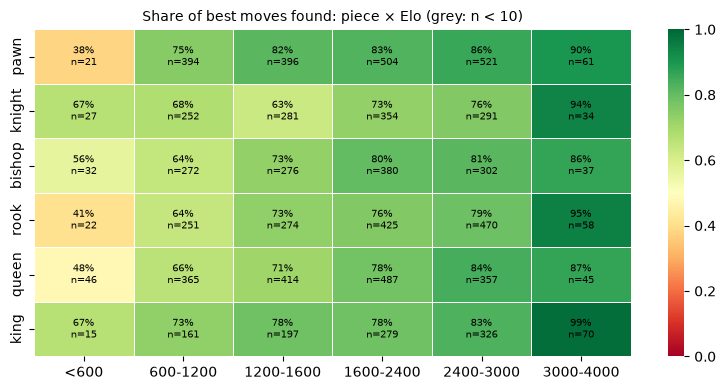

In [15]:
# 1) piece: how many positions / how many critical / how often the decision is good
bk.plot_piece_overview(dfn); plt.show()

# 2) piece x half of the board
bk.plot_half(dfn); plt.show()

# 3) piece x file (a-h)
bk.plot_piece_file(dfn, MIN_N); plt.show()

# 4) everything at once: piece x file x half (96 buckets)
bk.plot_full_buckets(dfn, MIN_N); plt.show()

# 4b) the same, but two big plots: OUR half | OPPONENT's half (rows = pieces, columns = a-h)
bk.plot_piece_file_by_half(dfn, MIN_N); plt.show()

# 5) piece x Elo bin (you can change the bins)


bk.plot_piece_elo(dfn, bins = [0,600, 1200, 1600,2400 ,3000,4000],
                 labels = ['<600','600-1200' ,'1200-1600', '1600-2400', '2400-3000','3000-4000'], min_n=MIN_N); plt.show()

### Defence against check
A position counts as a **defence against check** when the side to move is in check (the `in_check` column, computed from the FEN, so nothing needs to be analysed again). Every legal move is then a defence, and positions with a single legal move are skipped anyway.

,check_status,n_positions,n_critical,n_found,critical_share,found_rate,ci_low,ci_high
0,defence against check,9119,1323,1111,0.145082,0.839758,0.819012,0.858537
1,no check,123341,7374,5515,0.059785,0.747898,0.737860,0.757678


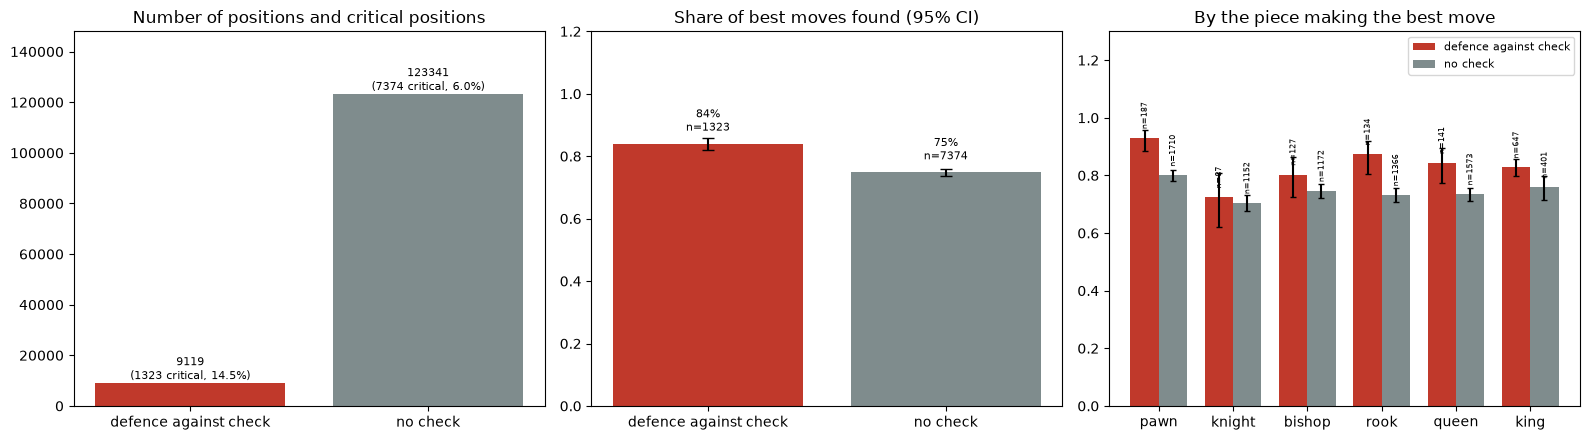

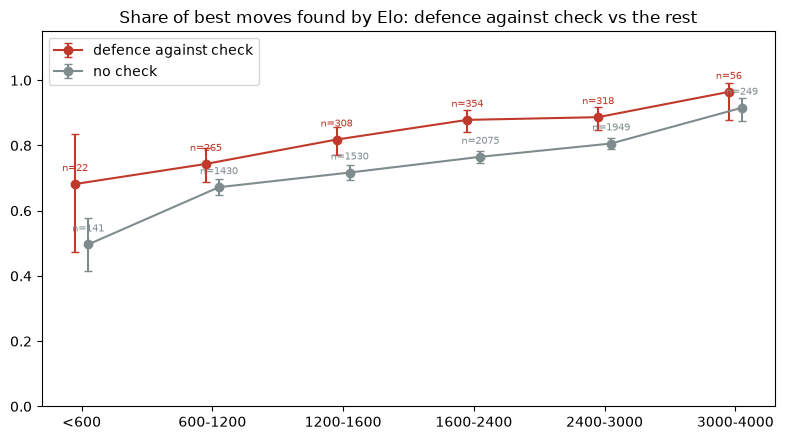

In [16]:
display(bk.summarize(dfn, ['check_status']))     # how many positions, how many critical, how often the decision is good

bk.plot_check(dfn); plt.show()                    # overall and by the piece making the best move
bk.plot_check_elo(dfn,bins = [0,600, 1200, 1600,2400 ,3000,4000],
                 labels = ['<600','600-1200' ,'1200-1600', '1600-2400', '2400-3000','3000-4000']); plt.show()

In [17]:
# full bucket table (for the thesis / Excel)
table = bk.bucket_table(dfn)
table.to_csv('../data/bucket_summary.csv', index=False)
table.sort_values('n_critical', ascending=False).head(20)

,best_piece,half,best_file,check_status,n_positions,n_critical,n_found,critical_share,found_rate,ci_low,ci_high
131,queen,own half,d,no check,5564,438,329,0.078720,0.751142,0.708585,0.789331
7,pawn,own half,d,no check,4390,258,210,0.058770,0.813953,0.761987,0.856707
11,pawn,own half,f,no check,3330,226,186,0.067868,0.823009,0.767973,0.867247
103,rook,own half,f,no check,3282,207,162,0.063071,0.782609,0.721545,0.833374
101,rook,own half,e,no check,2211,205,159,0.092718,0.775610,0.713732,0.827348
9,pawn,own half,e,no check,3877,198,163,0.051070,0.823232,0.764094,0.870066
168,king,own half,g,defence against check,1421,196,169,0.137931,0.862245,0.806993,0.903570
3,pawn,own half,b,no check,3021,192,168,0.063555,0.875000,0.820744,0.914544
39,knight,own half,f,no check,3998,192,131,0.048024,0.682292,0.613410,0.744022
99,rook,own half,d,no check,2325,173,136,0.074409,0.786127,0.719158,0.840665


## Notes and limitations
- The result depends on the depth (`depth`) and the threshold (`gap_threshold`) - describe the chosen values in the thesis and check the sensitivity (e.g. 0.15 / 0.20 / 0.30).
- Forced moves (1 legal move) are skipped; checks with a single sensible reply are *not* skipped, so part of the critical positions are obvious defences against check - a `board.is_check()` filter can be added.
- Time control (bullet vs classical) strongly affects mistakes - consider filtering by `TimeControl`.
- A sample of 100 games is only a functionality test; conclusions need several thousand games.